In [1]:
import pandas as pd
import spacy
import rapidfuzz
import re
nlp = spacy.blank("en")

In [2]:
# Read the jsonl files
extractions_df = pd.read_json("extractions_corrected.jsonl", lines=True)
result_all_df = pd.read_json("result-all.jsonl", lines=True)
key_cols = ["document_id", "extraction_text"]

result_flat = result_all_df.explode("extractions", ignore_index=True)
extraction_cols = pd.json_normalize(result_flat["extractions"])

# Keep parent columns except nested list
result_flat = pd.concat(
    [
        result_flat.drop(columns=["extractions"]).reset_index(drop=True),
        extraction_cols.reset_index(drop=True),
    ],
    axis=1,
)
# Remove overlapping non-key columns from right side
overlap_cols = [
    c for c in result_flat.columns
    if c in extractions_df.columns and c not in key_cols
]

# The documentation contains some duplicates "advices", guess due to divs for styling actually
# 92   actions/how-tos/manage-runners/self-hosted-run...   
# 93   actions/how-tos/manage-runners/self-hosted-run...   
# 549  code-security/how-tos/secure-your-secrets/cust...   
# 550  code-security/how-tos/secure-your-secrets/cust...   

#                                        extraction_text  
# 92   We recommend that you only use self-hosted run...  
# 93   We recommend that you only use self-hosted run...  
# 549  You can configure secret scanning to check pus...  
# 550  You can configure secret scanning to check pus... 

#extractions_df = extractions_df.drop_duplicates(key_cols)
result_flat = result_flat.drop_duplicates(key_cols)
result_flat = result_flat.drop(columns=overlap_cols + ["attributes","attributes._unused","description","extraction_class"])

# keep original data in place, use many_to_any join
merged_df = extractions_df.merge(
    result_flat,
    on=key_cols,
    how="left",
    validate="many_to_one",
)

columns_int = "extraction_index,group_index,char_interval.start_pos,char_interval.end_pos".split(",")
merged_df[columns_int] = merged_df[columns_int].astype(int)
columns_str = "document_id,extraction_text,text,alignment_status".split(",")
merged_df[columns_str] = merged_df[columns_str].astype("string")
merged_df["true_text"] = merged_df.apply(
    lambda row: row["text"][
        row["char_interval.start_pos"] : row["char_interval.end_pos"]
    ],
    axis=1,
)
merged_df["true_text"] = merged_df["true_text"].astype("string")
split_cols = merged_df["document_id"].str.split("/", expand=True)
merged_df["topic"] = split_cols[0]
merged_df["kind"] = split_cols[1]
merged_df["actionable"] = merged_df["final_classification"].apply(lambda x: isinstance(x, list) and len(x) > 0)
merged_df["add_actionable"] = merged_df["final_classification"].apply(lambda x: "+" in x)

overlap_df = pd.read_csv("github_owasp_overlap_by_id.csv")
def _as_class_items(value):
    if isinstance(value, list):
        return value
    if pd.isna(value):
        return []
    return [str(value)]
owasp_actionable_ids = set(
    overlap_df.loc[overlap_df["owasp_actionable"].astype(bool),
        "_id",
    ].astype(str)
)
merged_df["owasp_actionable"] = merged_df["actionable"] & ~merged_df["add_actionable"] 
merged_df["owasp_sbp"] = merged_df["final_classification"].apply(
    lambda value: any(item in owasp_actionable_ids for item in _as_class_items(value))
)
merged_df["mappings"] = merged_df["final_classification"].apply(len)

merged_df.sample(5)

,document_id,extraction_text,owasp_classification,final_classification,text,alignment_status,extraction_index,group_index,char_interval.start_pos,char_interval.end_pos,true_text,topic,kind,actionable,add_actionable,owasp_actionable,owasp_sbp,mappings
436,code-security/tutorials/trialing-github-advanc...,Copilot Autofix helps developers understand an...,[],[],# Exploring your enterprise trial of GitHub Co...,match_exact,3,2,10791,11080,Copilot Autofix helps developers understand an...,code-security,tutorials,False,False,False,False,0
240,code-security/concepts/supply-chain-security/b...,**Version control and change management** * T...,"[OWASP/1.1.1, OWASP/3.3.3]",[OWASP/3.8.1],# Best practices for maintaining dependencies ...,match_exact,8,7,2203,2426,**Version control and change management** * T...,code-security,concepts,True,False,True,False,1
330,code-security/how-tos/secure-your-supply-chain...,You need to ensure that the `.npmrc` file is c...,"[OWASP/3.6.1, OWASP/6.5.1]",[],# Guidance for the configuration of private re...,match_exact,2,1,14553,14819,You need to ensure that the `.npmrc` file is c...,code-security,how-tos,False,False,False,False,0
285,code-security/how-tos/scan-code-for-vulnerabil...,> [!WARNING] > CodeQL debugging artifacts cont...,[],[],# Logs are not detailed enough If you'd like ...,match_fuzzy,1,0,615,824,> \[!WARNING] > CodeQL debugging artifacts con...,code-security,how-tos,False,False,False,False,0
214,code-security/concepts/secret-security/github-...,When you store the sensitive information as a ...,"[OWASP/6.5.1, OWASP/6.7.1]",[],# GitHub secret types Learn about the differe...,match_exact,1,0,202,487,When you store the sensitive information as a ...,code-security,concepts,False,False,False,False,0


In [3]:
merged_df[~merged_df["owasp_sbp"] & merged_df["owasp_actionable"]] 

,document_id,extraction_text,owasp_classification,final_classification,text,alignment_status,extraction_index,group_index,char_interval.start_pos,char_interval.end_pos,true_text,topic,kind,actionable,add_actionable,owasp_actionable,owasp_sbp,mappings
13,actions/concepts/security/script-injections.md,"When creating workflows, [custom actions](/en/...",[],[OWASP/4.2.2],# Script injections Understand the security r...,match_exact,1,0,164,1189,"When creating workflows, [custom actions](/en/...",actions,concepts,True,False,True,False,1
14,actions/concepts/security/script-injections.md,By adopting the same defensive programming pos...,[],[OWASP/4.2.1],# Script injections Understand the security r...,match_exact,2,1,1190,1551,By adopting the same defensive programming pos...,actions,concepts,True,False,True,False,1
15,actions/concepts/security/script-injections.md,"In addition, there are other less obvious sour...",[],[OWASP/4.2.2],# Script injections Understand the security r...,match_exact,3,2,1553,1873,"In addition, there are other less obvious sour...",actions,concepts,True,False,True,False,1
45,actions/how-tos/manage-runners/self-hosted-run...,We recommend that you only use self-hosted run...,"[OWASP/4.2.1, OWASP/4.2.2]",[OWASP/4.2.2],# Adding self-hosted runners You can add a se...,match_fuzzy,1,0,132,541,We recommend that you only use self-hosted run...,actions,how-tos,True,False,True,False,1
46,actions/how-tos/manage-runners/self-hosted-run...,The custom script must be located on the runne...,[OWASP/5.4.1],[OWASP/7.3.1],# Customizing the containers used by jobs You...,match_exact,1,0,13121,13434,The custom script must be located on the runne...,actions,how-tos,True,False,True,False,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
404,code-security/tutorials/remediate-leaked-secre...,"Once services are back up and running, it's im...","[OWASP/10.2.3, OWASP/10.3.1]",[OWASP/10.2.3],# Remediating a leaked secret in your reposito...,match_exact,5,4,9747,9970,"Once services are back up and running, it's im...",code-security,tutorials,True,False,True,False,1
406,code-security/tutorials/remediate-leaked-secre...,Ensure that push protection (part of GitHub Se...,"[OWASP/6.5.1, OWASP/6.5.3]",[OWASP/1.1.2],# Remediating a leaked secret in your reposito...,match_exact,7,6,13010,13323,Ensure that push protection (part of GitHub Se...,code-security,tutorials,True,False,True,False,1
414,code-security/tutorials/secure-your-dependenci...,To ensure your project's security updates get ...,[OWASP/1.1.1],[OWASP/3.8.1],# Customizing Dependabot pull requests to fit ...,match_exact,2,1,1189,1504,To ensure your project's security updates get ...,code-security,tutorials,True,False,True,False,1
417,code-security/tutorials/secure-your-organizati...,Protect your organization's repositories and s...,[OWASP/2.4.3],[OWASP/2.4.3],# Best practices for preventing data leaks in ...,match_exact,1,0,1199,1395,Protect your organization's repositories and s...,code-security,tutorials,True,False,True,False,1


In [4]:
print(f"Documents that have at least one extraction: {merged_df.groupby("document_id").size().count()}")

Documents that have at least one extraction: 216


# Analyze Fuzzy Matches

In [5]:
fuzzy = merged_df[merged_df["alignment_status"] == "match_fuzzy"]
len(fuzzy)

30

In [6]:
from collections import Counter
rows = []
for _,row in fuzzy.iterrows():
    fuzzy_text = row["extraction_text"]
    org_text = row["true_text"]
    pred_tokens = [token.text.lower() for token in nlp.make_doc(fuzzy_text.strip())]
    gold_tokens = [token.text.lower() for token in nlp.make_doc(org_text.strip())]
    rows.append({
        "file" : row["document_id"],
        "true" : org_text,
        "pred" : fuzzy_text,
        "diff" : Counter(gold_tokens) - Counter(pred_tokens)
    })
[obj["diff"] for obj in rows]

[Counter({'github\\\\\\_token': 1}),
 Counter({'\\[!warning': 1}),
 Counter({'\\[!note': 1}),
 Counter({'>': 1}),
 Counter({'\n': 2, '>': 2}),
 Counter({'\n': 2, '>': 2}),
 Counter({'\n': 2, '>': 2}),
 Counter({'\\[!note': 1}),
 Counter({'\\[!note': 1}),
 Counter({'\\[!note': 1}),
 Counter({'\\[!warning]the': 1}),
 Counter({'\\[!tip': 1}),
 Counter({'github\\\\\\_token': 1}),
 Counter({'\\[!warning': 1}),
 Counter({'github\\\\\\_token': 1}),
 Counter({'\\[!warning': 1}),
 Counter({'github\\\\\\_token': 1}),
 Counter({'github\\\\\\_token': 1}),
 Counter({'github\\\\\\_token': 1}),
 Counter({'\\[!important': 1}),
 Counter({'github\\\\\\_token': 1}),
 Counter({'github\\\\\\_token': 1}),
 Counter({'\\[!note': 1}),
 Counter({'\\[!note': 1}),
 Counter({'>': 4, '\n': 2}),
 Counter({'\\[!warning': 1}),
 Counter({'\\[!warning': 1}),
 Counter({'#': 3,
          'the': 1,
          'of': 1,
          'alerts': 1,
          '\n\n': 1,
          'verify': 1,
          'accuracy': 1,
          'and'

# Extraction sizes

In [7]:
merged_df["extraction_size"] = merged_df["extraction_text"].str.split().str.len()
merged_df["extraction_size"].describe(percentiles=[0.5,0.90])

count    459.000000
mean      48.849673
std       34.172138
min        9.000000
50%       43.000000
90%       75.000000
max      484.000000
Name: extraction_size, dtype: float64

In [8]:
merged_df.sort_values("extraction_size",ascending=False).head(10)["extraction_text"].to_list()

["This list describes the recommended approaches for accessing repository data within a workflow, in descending order of preference:\n\n1. **The `GITHUB_TOKEN`**\n* This token is intentionally scoped to the single repository that invoked the workflow, and can have the same level of access as a write-access user on the repository. The token is created before each job begins and expires when the job is finished. For more information, see [Use GITHUB\\_TOKEN for authentication in workflows](/en/actions/security-guides/automatic-token-authentication).\n* The `GITHUB_TOKEN` should be used whenever possible.\n2. **Repository deploy key**\n* Deploy keys are one of the only credential types that grant read or write access to a single repository, and can be used to interact with another repository within a workflow. For more information, see [Managing deploy keys](/en/authentication/connecting-to-github-with-ssh/managing-deploy-keys#deploy-keys).\n* Note that deploy keys can only clone and push

# Unique extractions

In [9]:
len(merged_df["true_text"].unique())

421

In [10]:
import pandas as pd
from rapidfuzz import fuzz, process

advice_df = merged_df.copy()

def normalize_text(text):
    # Added basic lowering/stripping to make token_set_ratio case-insensitive
    return str(text).strip().lower()

advice_df["normalized_text"] = advice_df["true_text"].map(normalize_text)

cluster_reps = []
cluster_ids = []
cluster_scores = [] 

for text in advice_df["normalized_text"]:
    if not cluster_reps:
        cluster_ids.append(0)
        cluster_scores.append(100.0) 
        cluster_reps.append(text)
    else:
        match = process.extractOne(
            text, cluster_reps, scorer=fuzz.token_sort_ratio, score_cutoff=85
        )
        if match:
            _, score, best_cluster_idx = match
            cluster_ids.append(best_cluster_idx)
            cluster_scores.append(score)  
        else:
            new_cluster_idx = len(cluster_reps)
            cluster_ids.append(new_cluster_idx)
            cluster_scores.append(100.0)  
            cluster_reps.append(text)

# Create the new column in your main dataframe
advice_df["cluster_id"] = cluster_ids
advice_df["cluster_score"] = cluster_scores  

# Aggregate while preserving document_id, true_text, and scores for all items
cluster_summary = (
    advice_df.groupby("cluster_id")
    .agg(
        representative=("true_text", "first"),
        count=("true_text", "size"),
        document_ids=("document_id", list),
        matched_texts=("true_text", list),
        similarity_scores=("cluster_score", list),
    )
    .reset_index()
    .sort_values(["count", "cluster_id"], ascending=[False, True])
)

advice_df["unique"] = ~advice_df.duplicated(subset=["cluster_id"], keep="first")
merged_df = advice_df.copy()

print(f"\n===\nFound {cluster_summary["count"].sum() - cluster_summary["count"].count()} dups\n===\n")

cluster_summary


===
Found 45 dups
===



,cluster_id,representative,count,document_ids,matched_texts,similarity_scores
52,52,"Before proceeding, you must plan your security...",8,[actions/how-tos/secure-your-work/security-har...,"[Before proceeding, you must plan your securit...","[100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 100..."
21,21,> \[!WARNING] > When creating workflows and ac...,7,[actions/concepts/workflows-and-actions/contex...,[> \[!WARNING]\n> When creating workflows and ...,"[100.0, 100.0, 98.08153477218225, 98.081534772..."
54,54,> \[!NOTE] > When environments are used in wor...,7,[actions/how-tos/secure-your-work/security-har...,[> \[!NOTE]\n> When environments are used in w...,"[100.0, 98.69608826479438, 98.69608826479438, ..."
407,407,For registries that support granular permissio...,5,[packages/managing-github-packages-using-githu...,[For registries that support granular permissi...,"[100.0, 100.0, 96.29018961253092, 96.290189612..."
44,44,We recommend that you only use self-hosted run...,3,[actions/how-tos/manage-runners/self-hosted-ru...,[We recommend that you only use self-hosted ru...,"[100.0, 100.0, 100.0]"
...,...,...,...,...,...,...
409,409,All workflows accessing registries that suppor...,1,[packages/managing-github-packages-using-githu...,[All workflows accessing registries that suppo...,[100.0]
410,410,If you're using a registry that supports granu...,1,[packages/managing-github-packages-using-githu...,[If you're using a registry that supports gran...,[100.0]
411,411,"By default, when you select the `write:package...",1,[packages/working-with-a-github-packages-regis...,"[By default, when you select the `write:packag...",[100.0]
412,412,"To ensure you're always using the same image, ...",1,[packages/working-with-a-github-packages-regis...,"[To ensure you're always using the same image,...",[100.0]


In [11]:
fuzzy_clusters = cluster_summary[
    (cluster_summary["count"] > 1)
    & cluster_summary["similarity_scores"].apply(
        lambda scores: any(s > 95.0 for s in scores)
    )
]
for _, row in fuzzy_clusters.iterrows():
    print(f"Cluster Representative: {row['representative']}")
    for doc, text, score in zip(
        row["document_ids"], row["matched_texts"], row["similarity_scores"]
    ):
        print(f"\t [Score: {score:.1f}] @ Doc ID: {doc}\n\t *Text*: {text}\n")
    print("-" * 100)

Cluster Representative: Before proceeding, you must plan your security strategy to ensure that access tokens are only allocated in a predictable way. To control how your cloud provider issues access tokens, you **must** define at least one condition, so that untrusted repositories can’t request access tokens for your cloud resources. For more information, see [OpenID Connect](/en/actions/deployment/security-hardening-your-deployments/about-security-hardening-with-openid-connect#configuring-the-oidc-trust-with-the-cloud).
	 [Score: 100.0] @ Doc ID: actions/how-tos/secure-your-work/security-harden-deployments/oidc-in-aws.md
	 *Text*: Before proceeding, you must plan your security strategy to ensure that access tokens are only allocated in a predictable way. To control how your cloud provider issues access tokens, you **must** define at least one condition, so that untrusted repositories can’t request access tokens for your cloud resources. For more information, see [OpenID Connect](/en/a

## Due diligence: Ensure consistent OWASP assignments for similar extractions (85%+ match)

In [12]:

def get_owasp_for_cluster(cluster_id):
    """Get OWASP classifications for all items in a cluster"""
    cluster_row = cluster_summary[cluster_summary["cluster_id"] == cluster_id].iloc[0]
    owasp_lists = []
    
    for idx, doc_id in enumerate(cluster_row["document_ids"]):
        # Find the row in merged_df with this document_id and matched text
        matched_text = cluster_row["matched_texts"][idx]
        mask = (merged_df["document_id"] == doc_id) & (merged_df["true_text"] == matched_text)
        rows = merged_df[mask]
        
        if len(rows) > 0:
            owasp = rows.iloc[0]["final_classification"]
            owasp_lists.append({
                "document_id": doc_id,
                "similarity_score": cluster_row["similarity_scores"][idx],
                "final_classification": owasp,
                "text_preview": matched_text[:80]
            })
    
    return owasp_lists

# Check for inconsistencies in high-similarity clusters
inconsistencies = []
for cluster_id in cluster_summary["cluster_id"]:
    owasp_data = get_owasp_for_cluster(cluster_id)
    
    # Filter for items with 85%+ similarity
    high_sim = [item for item in owasp_data if item["similarity_score"] >= 85.0]
    
    if len(high_sim) > 1:
        # Check if final_classification differ
        owasp_set = [str(item["final_classification"]) for item in high_sim]
        if len(set(owasp_set)) > 1:
            inconsistencies.append({
                "cluster_id": cluster_id,
                "count": len(high_sim),
                "owasp_data": high_sim
            })

print(f"Found {len(inconsistencies)} clusters with inconsistent final classifications (85%+ similarity)")
print("\nInconsistencies details:")
for inc in inconsistencies:
    print(f"\n--- Cluster {inc['cluster_id']} ({inc['count']} high-similarity items) ---")
    for item in inc["owasp_data"]:
        print(f"  Score: {item['similarity_score']:.1f}% | Final: {item['final_classification']}")
        print(f"    Doc: {item['document_id']}")
        print(f"    Text: {item['text_preview']}...")

Found 0 clusters with inconsistent final classifications (85%+ similarity)

Inconsistencies details:


# Location and actionable

In [13]:
print(f"""
Actionable: {merged_df["actionable"].sum()}
Actionable and unique: {(merged_df["actionable"] & merged_df["unique"]).sum()}
""")


Actionable: 288
Actionable and unique: 257



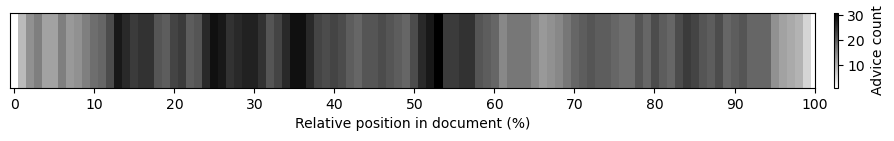

In [14]:
# Location distribution and actionable

import numpy as np
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.pyplot as plt

advices = merged_df[
    merged_df["actionable"]
].copy()

doc_size = advices["text"].str.len()
advices["start_rel"] = advices["char_interval.start_pos"] / doc_size
advices["end_rel"] = advices["char_interval.end_pos"] / doc_size

n_buckets = 100
counts = np.zeros(n_buckets, dtype=int)

# i know u can use a sweep algo but this does it for now
for start_rel, end_rel in advices[["start_rel", "end_rel"]].dropna().itertuples(index=False):
    start_idx = max(0, min(n_buckets - 1, int(np.floor(start_rel * n_buckets))))
    end_idx = max(0, min(n_buckets - 1, int(np.ceil(end_rel * n_buckets)) - 1))
    if end_idx < start_idx:
        start_idx, end_idx = end_idx, start_idx
    counts[start_idx : end_idx + 1] += 1

heat = counts[np.newaxis, :]
cmap = LinearSegmentedColormap.from_list("white_to_dark", ["#ffffff", "#000000"])
plt.figure(figsize=(10, 1.5))
plt.imshow(heat, aspect="auto", cmap=cmap, interpolation="nearest")
plt.yticks([])
plt.xticks(np.arange(0,110,step=10), [str(x*10) for x in range(0,11)])
plt.xlabel("Relative position in document (%)")
plt.colorbar(label="Advice count", orientation="vertical", pad=0.02)
plt.tight_layout()
plt.savefig("advice-location.pdf", bbox_inches="tight")
plt.show()


## Distribution

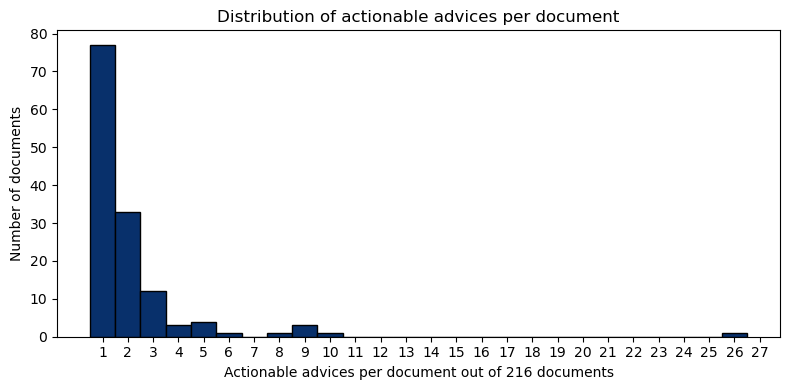

In [15]:
actionable = merged_df[merged_df["actionable"]]
counts = actionable.groupby("document_id").size()

plt.figure(figsize=(8, 4))
if len(counts) > 0:
    bins = range(1, int(counts.max()) + 2)
    plt.hist(counts, bins=bins, align='left', color="#08306b", edgecolor="k")
    plt.xticks(bins)
else:
    plt.hist([], bins=[0, 1], color="#08306b", edgecolor="k")
    plt.xticks([0, 1])

plt.xlabel(f"Actionable advices per document out of {merged_df["document_id"].nunique()} documents")
plt.ylabel("Number of documents")
plt.title("Distribution of actionable advices per document")
plt.tight_layout()
plt.show()

In [16]:
# Distribution of actionable advices per document
actionable = merged_df[merged_df["actionable"]]
counts = actionable.groupby("document_id").size()

print(f"Advice docs: {len(counts)}")
print("Distribution of actionable advices per document:")
distribution = counts.value_counts().sort_index()
for num_advices, num_docs in distribution.items():
    print(f"  {num_advices} advice(s): {num_docs} document(s)")

# Advice rate and density metrics
total_advice_words = actionable["extraction_size"].sum()
total_docs_words = 3387939 # jq 'reduce .[] as $item (0; . + $item.words)' analyzed_preprocessed.json
total_actionable = len(actionable)

advice_rate_per_1000_words = (total_actionable / total_docs_words) * 1000
words_per_advice = total_docs_words / total_actionable
advice_coverage = total_advice_words / total_docs_words

print(f"\n--- Advice Density Metrics ---")
print(f"Total actionable extractions: {total_actionable}")
print(f"Total words in actionable extractions: {total_advice_words}")
print(f"Total documentation words: {total_docs_words}")
print(f"Advice rate: {advice_rate_per_1000_words:.4f} per 1000 words")
print(f"Advice coverage: {advice_coverage}")
print(f"Words after seeing one advice: {words_per_advice:.1f}")

Advice docs: 136
Distribution of actionable advices per document:
  1 advice(s): 77 document(s)
  2 advice(s): 33 document(s)
  3 advice(s): 12 document(s)
  4 advice(s): 3 document(s)
  5 advice(s): 4 document(s)
  6 advice(s): 1 document(s)
  8 advice(s): 1 document(s)
  9 advice(s): 3 document(s)
  10 advice(s): 1 document(s)
  26 advice(s): 1 document(s)

--- Advice Density Metrics ---
Total actionable extractions: 288
Total words in actionable extractions: 15007
Total documentation words: 3387939
Advice rate: 0.0850 per 1000 words
Advice coverage: 0.004429536659308211
Words after seeing one advice: 11763.7


In [17]:
actionable = merged_df[merged_df["actionable"]]

counts = actionable.groupby("document_id").size().sort_values(ascending=False)
top_document_id = counts.index[0]
top_count = int(counts.iloc[0])

print(f"Document with the most advices: {top_document_id}")
print(f"Number of advices: {top_count}")

Document with the most advices: actions/reference/security/secure-use.md
Number of advices: 26


# Examples and alerts

Alert handling because there are not always extracted!

In [18]:
ALERT_PATTERN = re.compile(r"\[!(WARNING|NOTE|TIP|IMPORTANT|CAUTION)\](?:\n>)?", flags=re.IGNORECASE)
LOOKBACK_CHARS = 15

def _visual_alert_info(row, lookback=LOOKBACK_CHARS):
    text = str(row["text"])
    start = int(row["char_interval.start_pos"])
    end = int(row["char_interval.end_pos"])

    context = text[max(0, start - lookback):end]
    m_ctx = ALERT_PATTERN.search(context)
    m_org = ALERT_PATTERN.search(row["true_text"])

    return pd.Series(
        {
            "context_window": row["true_text"] if m_ctx is None else context[m_ctx.end():],
            "has_visual_alert": m_ctx is not None,
            "has_visual_alert_org": m_org is not None,
            "type": (m_ctx.group(1).upper() if m_ctx else pd.NA),
        }
    )

alert_info = merged_df.apply(_visual_alert_info, axis=1)
merged_df = pd.concat([merged_df, alert_info], axis=1)
merged_df.sample(5)

,document_id,extraction_text,owasp_classification,final_classification,text,alignment_status,extraction_index,group_index,char_interval.start_pos,char_interval.end_pos,...,mappings,extraction_size,normalized_text,cluster_id,cluster_score,unique,context_window,has_visual_alert,has_visual_alert_org,type
347,code-security/reference/supply-chain-security/...,"If a security update times out, you can reduce...","[OWASP/3.3.3, OWASP/3.8.1]",[],# Dependabot errors Dependabot automatically ...,match_exact,2,1,8881,9200,...,0,33,"if a security update times out, you can reduce...",309,100.0,True,"If a security update times out, you can reduce...",False,False,<NA>
197,actions/tutorials/use-actions-runner-controlle...,"As a security best practice, create your runne...","[OWASP/5.5.1, OWASP/5.5.2, OWASP/5.7.1]","[OWASP/5.5.1, OWASP/5.5.2, OWASP/5.7.1]",# Quickstart for Actions Runner Controller In...,match_exact,1,0,3577,3704,...,3,20,"as a security best practice, create your runne...",160,100.0,False,"\n> * As a security best practice, create your...",True,False,NOTE
254,code-security/concepts/vulnerability-reporting...,Regularly assessing your exposure to vulnerabi...,[OWASP/7.1.2],[OWASP/7.1.2],# About exposure to vulnerabilities in your co...,match_exact,1,0,2060,2249,...,1,23,regularly assessing your exposure to vulnerabi...,221,100.0,True,Regularly assessing your exposure to vulnerabi...,False,False,<NA>
432,code-security/tutorials/secure-your-organizati...,Focus remediation on real risk by targeting De...,[OWASP/7.1.2],[+],# Prioritizing Dependabot and code scanning al...,match_exact,1,0,77,321,...,1,35,focus remediation on real risk by targeting de...,392,100.0,True,Focus remediation on real risk by targeting De...,False,False,<NA>
322,code-security/how-tos/secure-your-supply-chain...,> \[!WARNING] You should not rely on the GitHu...,"[OWASP/5.5.2, OWASP/6.4.1, OWASP/7.2.1]",[OWASP/5.5.2],# Configuring Dependabot on GitHub-hosted runn...,match_exact,1,0,799,1271,...,1,56,> \[!warning] you should not rely on the githu...,285,100.0,True,You should not rely on the GitHub Actions IP ...,True,True,WARNING


In [19]:
actionable_key = "actionable" 
visual_alert_df = merged_df[merged_df["has_visual_alert"] & merged_df[actionable_key]].copy()
print(
    f"Before {merged_df['has_visual_alert_org'].sum()}, After {merged_df['has_visual_alert'].sum()}"
)
print(
    f"Before ACT {merged_df[merged_df['has_visual_alert_org'] & merged_df[actionable_key]]['has_visual_alert_org'].sum()}, "
    f"After ACT {merged_df[merged_df['has_visual_alert'] & merged_df[actionable_key]]['has_visual_alert'].sum()}"
)
print(f"Visual-alert extractions: {len(visual_alert_df)}")
print("\nBy type:")
print(visual_alert_df["type"].value_counts(dropna=False))
grouped = visual_alert_df.dropna().groupby(["topic", "type"]).size().unstack(fill_value=0)
grouped.sum(axis=1)

Before 28, After 82
Before ACT 22, After ACT 64
Visual-alert extractions: 64

By type:
type
WARNING      34
NOTE         27
TIP           2
IMPORTANT     1
Name: count, dtype: int64


topic
actions          55
code-security     7
packages          2
dtype: int64

In [20]:
actionable_key = "owasp_sbp"
visual_alert_df = merged_df[merged_df["has_visual_alert"] & merged_df[actionable_key]].copy()
print(
    f"Before {merged_df['has_visual_alert_org'].sum()}, After {merged_df['has_visual_alert'].sum()}"
)
print(
    f"Before ACT {merged_df[merged_df['has_visual_alert_org'] & merged_df[actionable_key]]['has_visual_alert_org'].sum()}, "
    f"After ACT {merged_df[merged_df['has_visual_alert'] & merged_df[actionable_key]]['has_visual_alert'].sum()}"
)
print(f"Visual-alert extractions: {len(visual_alert_df)}")
print("\nBy type:")
print(visual_alert_df["type"].value_counts(dropna=False))
grouped = visual_alert_df.dropna().groupby(["topic", "type"]).size().unstack(fill_value=0)
grouped.sum(axis=1)

Before 28, After 82
Before ACT 10, After ACT 31
Visual-alert extractions: 31

By type:
type
WARNING    16
NOTE       14
TIP         1
Name: count, dtype: int64


topic
actions          26
code-security     4
packages          1
dtype: int64

# OWASP and others

In [21]:
merged_df.columns

Index(['document_id', 'extraction_text', 'owasp_classification',
       'final_classification', 'text', 'alignment_status', 'extraction_index',
       'group_index', 'char_interval.start_pos', 'char_interval.end_pos',
       'true_text', 'topic', 'kind', 'actionable', 'add_actionable',
       'owasp_actionable', 'owasp_sbp', 'mappings', 'extraction_size',
       'normalized_text', 'cluster_id', 'cluster_score', 'unique',
       'context_window', 'has_visual_alert', 'has_visual_alert_org', 'type'],
      dtype='object')

In [22]:
# Filter for actionable extractions only
actionable_df = merged_df[merged_df["actionable"]].copy()

actionable_df["classification"] = "other"
actionable_df.loc[actionable_df["add_actionable"], "classification"] = "additional"
actionable_df.loc[actionable_df["owasp_actionable"], "classification"] = "owasp_actionable"
actionable_df.loc[actionable_df["owasp_sbp"], "classification"] = "sbp"
# actionable_df[["owasp_actionable","actionable","add_actionable","classification"]]
summary = []
for topic in ["code-security", "actions", "packages"]:
    topic_data = actionable_df[actionable_df["topic"] == topic]
    total_actionable = len(topic_data)
    additional = len(topic_data[topic_data["classification"] == "additional"])
    sbp = len(topic_data[topic_data["classification"] == "sbp"])
    owasp_actionable = len(topic_data[topic_data["classification"] == "owasp_actionable"])
    
    summary.append({
        "Topic": topic,
        "Act.": total_actionable,
        "Add.": additional,
        "Act. OWASP": owasp_actionable,
        "SBP": sbp
    })

result_df = pd.DataFrame(summary)
print(result_df.sum() )
result_df 

Topic         code-securityactionspackages
Act.                                   288
Add.                                    78
Act. OWASP                              64
SBP                                    146
dtype: object


,Topic,Act.,Add.,Act. OWASP,SBP
0,code-security,125,47,24,54
1,actions,157,28,40,89
2,packages,6,3,0,3


In [23]:
print(result_df.to_latex(index=False))

\begin{tabular}{lrrrr}
\toprule
Topic & Act. & Add. & Act. OWASP & SBP \\
\midrule
code-security & 125 & 47 & 24 & 54 \\
actions & 157 & 28 & 40 & 89 \\
packages & 6 & 3 & 0 & 3 \\
\bottomrule
\end{tabular}



In [24]:
total_mappings = merged_df[merged_df["actionable"] & ~merged_df["add_actionable"]].groupby(by="mappings").size()

print(f"More than 1 mapping: {total_mappings.sum() - total_mappings[1]}")
total_mappings

More than 1 mapping: 90


mappings
1    120
2     54
3     28
4      4
5      2
6      1
7      1
dtype: int64

In [25]:
# Extract major OWASP categories
def _extract_major_owasp_list(final_cls,checkSBP = False):
    majors = []
    for it in final_cls:
        major = it.split("/", 1)[1].split(".")[0]
        if checkSBP and it not in owasp_actionable_ids:
            continue
        majors.append(f"OWASP/{major}")
    return majors

rep_df = merged_df[merged_df["unique"] & merged_df["owasp_actionable"]].copy()
majors = (
    rep_df["final_classification"]
    .apply(_extract_major_owasp_list)
    .explode()
    .dropna()
)

sbp_majors = (
    rep_df["final_classification"]
    .apply(_extract_major_owasp_list,checkSBP=True)
    .explode()
    .dropna()
)

# 1. Get the counts and sort them
counts = majors.value_counts().sort_index()
sbp_counts = sbp_majors.value_counts().sort_index()
df_table = counts.to_frame(name="count").reset_index()
df_table_sbp = sbp_counts.to_frame(name="sbp_count").reset_index()
df_table = pd.merge(df_table,df_table_sbp,on="final_classification")
df_table["relative"] = (100 * df_table["count"] / df_table["count"].sum()).round()
df_table["final_classification"] = df_table["final_classification"].apply(lambda x: f"{x.split('/', 1)[1]}")
df_table.rename(columns={"final_classification": "OWASP ID"}, inplace=True)
df_table


,OWASP ID,count,sbp_count,relative
0,1,22,19,7.0
1,10,6,5,2.0
2,2,16,11,5.0
3,3,44,20,14.0
4,4,37,9,12.0
5,5,30,19,10.0
6,6,102,68,33.0
7,7,20,12,6.0
8,8,5,1,2.0
9,9,27,17,9.0


In [26]:
# Frequency analysis of OWASP codes using ONLY `final_classification`

def _extract_owasp_codes(value):
    if isinstance(value, list):
        items = value
    elif pd.isna(value):
        items = []
    else:
        items = [str(value)]
    return [x for x in items if isinstance(x, str) and x.startswith("OWASP/")]

# 1) Global frequency (all rows in owasp_df)
global_counts = (
    merged_df[merged_df["owasp_sbp"]]["final_classification"]
    .apply(_extract_owasp_codes)
    .explode()
    .dropna()
    .value_counts()
    .rename("global_count")
)

global_freq = (
    global_counts.to_frame()
    .assign(global_pct=lambda d: (d["global_count"] / d["global_count"].sum() * 100).round(2))
)

rep_freq = (
    merged_df[merged_df["owasp_sbp"] & merged_df["unique"]]["final_classification"]
    .apply(_extract_owasp_codes)
    .explode()
    .dropna()
    .value_counts()
    .rename("global_count")
)

rep_freq = (
    rep_freq.to_frame()
    .assign(cluster_rep_pct=lambda d: (d["global_count"] / d["global_count"].sum() * 100).round(2))
)

print("Top OWASP codes (global):")
display(global_freq.head(20))

print("Top OWASP codes (unique actionable owasp_sbp):")
display(rep_freq.head(20))


Top OWASP codes (global):


,global_count,global_pct
final_classification,,
OWASP/6.4.1,18,6.87
OWASP/1.1.1,16,6.11
OWASP/6.5.1,15,5.73
OWASP/6.7.1,14,5.34
OWASP/6.3.1,14,5.34
OWASP/3.8.1,12,4.58
OWASP/4.1.1,12,4.58
OWASP/3.3.3,11,4.20
OWASP/3.3.2,9,3.44


Top OWASP codes (unique actionable owasp_sbp):


,global_count,cluster_rep_pct
final_classification,,
OWASP/1.1.1,16,6.72
OWASP/6.5.1,15,6.30
OWASP/6.7.1,14,5.88
OWASP/6.3.1,13,5.46
OWASP/3.8.1,12,5.04
OWASP/6.4.1,11,4.62
OWASP/9.1.1,8,3.36
OWASP/3.3.3,8,3.36
OWASP/9.1.5,7,2.94


In [27]:
# OWASP/3.8.1	23	7.44
# OWASP/1.1.1	16	5.18
# OWASP/6.5.1	15	4.85
target = "OWASP/3.8.1"
merged_df[merged_df["final_classification"].apply(lambda x: target in x)]

,document_id,extraction_text,owasp_classification,final_classification,text,alignment_status,extraction_index,group_index,char_interval.start_pos,char_interval.end_pos,...,mappings,extraction_size,normalized_text,cluster_id,cluster_score,unique,context_window,has_visual_alert,has_visual_alert_org,type
225,code-security/concepts/supply-chain-security/a...,Alerts can't catch every security issue. Alway...,"[OWASP/3.3.3, OWASP/3.8.1]","[OWASP/3.3.3, OWASP/3.8.1]",# About Dependabot alerts Dependabot alerts h...,match_exact,1,0,3552,3692,...,2,22,alerts can't catch every security issue. alway...,192,100.0,True,Alerts can't catch every security issue. Alway...,False,False,<NA>
228,code-security/concepts/supply-chain-security/a...,You can use the dependency review action in yo...,"[OWASP/1.1.1, OWASP/3.3.2, OWASP/3.8.1]","[OWASP/1.1.1, OWASP/3.8.1]",# About dependency review Dependency review l...,match_exact,2,1,3729,4152,...,2,63,you can use the dependency review action in yo...,195,100.0,True,You can use the dependency review action in yo...,False,False,<NA>
231,code-security/concepts/supply-chain-security/a...,One of the most important things you can do to...,"[OWASP/7.1.3, OWASP/7.1.4]",[OWASP/3.8.1],# About supply chain security GitHub helps yo...,match_exact,1,0,1128,1266,...,1,24,one of the most important things you can do to...,198,100.0,True,One of the most important things you can do to...,False,False,<NA>
235,code-security/concepts/supply-chain-security/b...,**Automate security patch management** * Conf...,"[OWASP/7.1.2, OWASP/7.1.3]","[OWASP/7.1.2, OWASP/3.8.1]",# Best practices for maintaining dependencies ...,match_exact,3,2,848,1080,...,2,33,**automate security patch management**\n\n* co...,202,100.0,True,**Automate security patch management**\n\n* Co...,False,False,<NA>
236,code-security/concepts/supply-chain-security/b...,**Enforce policies on the use of dependencies*...,"[OWASP/1.1.1, OWASP/3.3.2, OWASP/3.3.3]","[OWASP/1.1.1, OWASP/3.8.1]",# Best practices for maintaining dependencies ...,match_exact,4,3,1082,1337,...,2,39,**enforce policies on the use of dependencies*...,203,100.0,True,**Enforce policies on the use of dependencies*...,False,False,<NA>
239,code-security/concepts/supply-chain-security/b...,**Monitor security advisories** * Subscribe t...,"[OWASP/7.1.2, OWASP/7.1.3]","[OWASP/3.8.1, OWASP/7.1.2, OWASP/7.1.3]",# Best practices for maintaining dependencies ...,match_exact,7,6,1819,2201,...,3,56,**monitor security advisories**\n\n* subscribe...,206,100.0,True,**Monitor security advisories**\n\n* Subscribe...,False,False,<NA>
240,code-security/concepts/supply-chain-security/b...,**Version control and change management** * T...,"[OWASP/1.1.1, OWASP/3.3.3]",[OWASP/3.8.1],# Best practices for maintaining dependencies ...,match_exact,8,7,2203,2426,...,1,31,**version control and change management**\n\n*...,207,100.0,True,**Version control and change management**\n\n*...,False,False,<NA>
242,code-security/concepts/supply-chain-security/b...,**Response plan for vulnerabilities** * Have ...,[OWASP/3.8.1],[OWASP/3.8.1],# Best practices for maintaining dependencies ...,match_exact,10,9,2660,2871,...,1,31,**response plan for vulnerabilities**\n\n* hav...,209,100.0,True,**Response plan for vulnerabilities**\n\n* Hav...,False,False,<NA>
253,code-security/concepts/vulnerability-reporting...,"In contrast, malicious software, or malware, i...",[],[OWASP/3.8.1],# About the GitHub Advisory database The GitH...,match_exact,2,1,1995,2351,...,1,54,"in contrast, malicious software, or malware, i...",220,100.0,True,"In contrast, malicious software, or malware, i...",False,False,<NA>
255,code-security/concepts/vulnerability-reporting...,Use the metrics overview for Dependabot to gai...,[OWASP/7.1.2],[OWASP/3.8.1],# About exposure to vulnerabilities in your co...,match_exact,2,1,3614,3866,...,1,24,use the metrics overview for dependabot to gai...,222,100.0,True,Use the metrics overview for Dependabot to gai...,False,False,<NA>


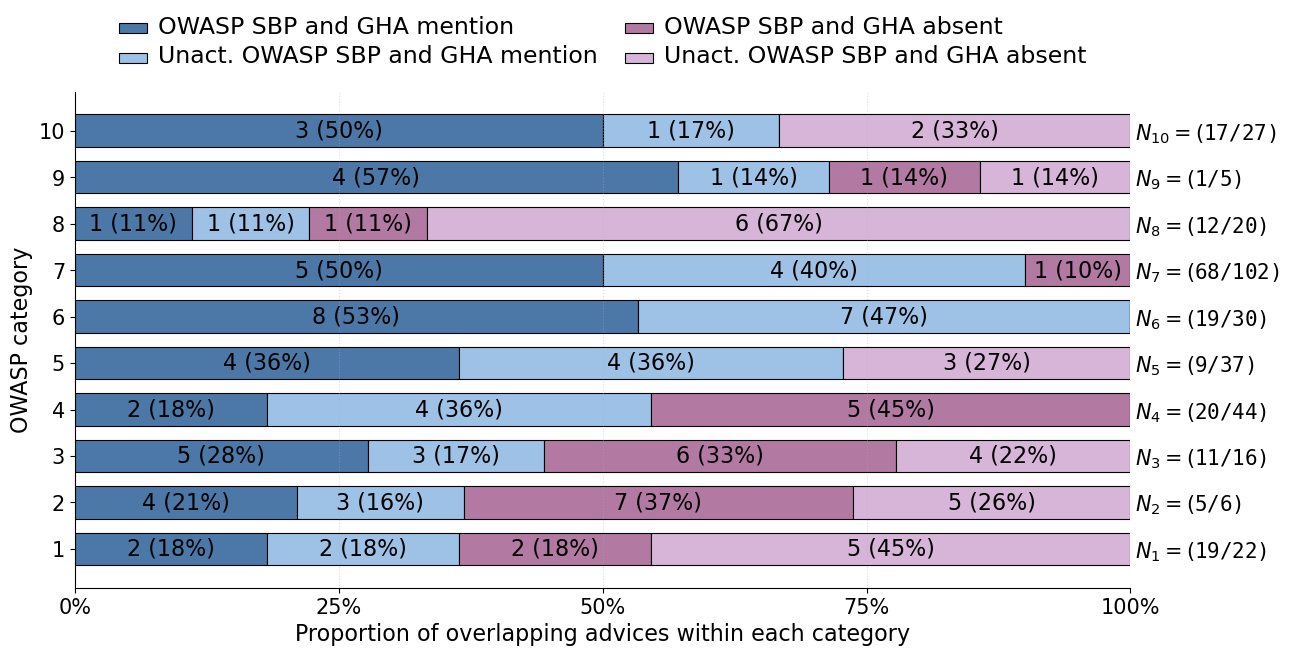

In [28]:
overlap_df = pd.read_csv("github_owasp_overlap_by_id.csv")

OVERLAP_ORDER = [
    "OWASP actionable and GitHub actionable",
    "Not OWASP actionable and GitHub actionable",
    "OWASP actionable and not GitHub actionable",
    "Not OWASP actionable and not GitHub actionable",
]

def _natural_key(value):
    parts = re.split(r"(\d+)", str(value))
    return tuple(int(p) if p.isdigit() else p.lower() for p in parts)

def plot_overlap_proportions(overlap_df: pd.DataFrame, output_path: str) -> None:
    df = overlap_df.copy()
    df["category_key"] = df["category_key"].astype(str)
    df["overlap_bucket"] = df["overlap_bucket"].astype(str)

    overlap_counts_by_category = (
        df.assign(
            category_label=df["category_key"],
            _category_sort=df["category_key"].map(_natural_key),
        )
        .groupby(["category_label", "_category_sort", "overlap_bucket"])
        .size()
        .unstack(fill_value=0)
        .reindex(columns=OVERLAP_ORDER, fill_value=0)
        .reset_index()
        .sort_values("_category_sort")
        .set_index("category_label")
        .drop(columns="_category_sort")
    )

    row_totals = overlap_counts_by_category.sum(axis=1).replace(0, pd.NA)
    proportions_by_category = overlap_counts_by_category.div(row_totals, axis=0).fillna(0)

    fills = {
        "OWASP actionable and GitHub actionable": {
            "color": "#4C78A8",  # muted blue
            "hatch": None
        },
        "Not OWASP actionable and GitHub actionable": {
            "color": "#9EC1E6",  # light blue
            "hatch": None
        },
        "OWASP actionable and not GitHub actionable": {
            "color": "#B279A2",  # muted purple
            "hatch": None
        },
        "Not OWASP actionable and not GitHub actionable": {
            "color": "#D7B5D8",  # light purple
            "hatch": None
        },
    }

    fig_height = max(5.4, 0.67 * len(proportions_by_category))
    fig, axis = plt.subplots(figsize=(13, fig_height))
    left = pd.Series(0.0, index=proportions_by_category.index)

    for bucket in OVERLAP_ORDER:
        widths = proportions_by_category[bucket]
        bars = axis.barh(
            proportions_by_category.index,
            widths,
            left=left,
            color=fills[bucket]["color"],
            hatch=fills[bucket]["hatch"],
            edgecolor="black",
            linewidth=0.8,
            height=0.7,
            label=bucket,
        )
        counts = overlap_counts_by_category[bucket]
        for bar, width, count in zip(bars, widths, counts):
            if width < 0.08:
                continue
            axis.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_y() + bar.get_height() / 2,
                f"{int(count)} ({width * 100:.0f}%)",
                ha="center",
                va="center",
                fontsize=16,
            )
        left = left + widths

    axis.set_xlim(0, 1)
    axis.set_xlabel("Proportion of overlapping advices within each category", fontsize=16)
    axis.set_ylabel("OWASP category", fontsize=16)
    axis.set_xticks([0, 0.25, 0.5, 0.75, 1.0])
    axis.set_xticklabels(["0%", "25%", "50%", "75%", "100%"])
    axis.tick_params(axis="both", labelsize=15)
    axis.spines["top"].set_visible(False)
    axis.spines["right"].set_visible(False)
    axis.grid(axis="x", linestyle=":", alpha=0.4)

    ax2 = axis.twinx()
    ax2.set_ylim(axis.get_ylim())
    ax2.set_yticks(axis.get_yticks())
    
    right_labels = list(
        df_table.apply(
            lambda x: f"$N_{{{x.name+1}}}=(${x['sbp_count']}/{x['count']})",
            axis=1
        )
    )
    ax2.set_yticklabels(right_labels, fontfamily="monospace")
    ax2.tick_params(axis="y", labelsize=15, length=0)
    
    # Hide all spines on the secondary axis
    for spine in ax2.spines.values():
        spine.set_visible(False)

    legend = axis.legend(loc="upper center", bbox_to_anchor=(0.5, 1.18), ncol=2, frameon=False)
    for text in legend.get_texts():
        text.set_text(text.get_text().replace("not GitHub actionable", "GHA absent"))
        text.set_text(text.get_text().replace("GitHub actionable", "GHA mention"))
        text.set_text(text.get_text().replace("Not OWASP actionable", "Unact. OWASP SBP"))
        text.set_text(text.get_text().replace("OWASP actionable", "OWASP SBP"))
        
        text.set_fontsize(17)

    fig.tight_layout()
    fig.savefig(output_path, bbox_inches="tight")
    plt.show()
    plt.close(fig)

plot_overlap_proportions(overlap_df,"github_owasp_overlap_proportions.pdf")

# Topic and kind analysis

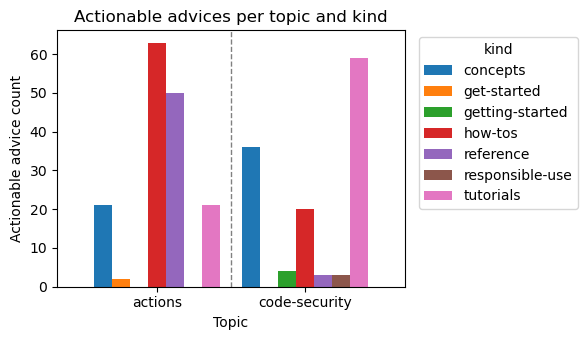

In [29]:
actionable = merged_df[merged_df["actionable"]]
actionable = actionable[actionable.topic != "packages"]
df_counts = actionable.groupby(['topic','kind']).size().reset_index(name='count')

# pivot so each topic is a row and each kind a separate bar (columns)
pivot = df_counts.pivot(index='topic', columns='kind', values='count').fillna(0).astype(int)

ax = pivot.plot(kind="bar", figsize=(6, 3.5), width=0.85)

ax.set_xlabel("Topic")
ax.set_ylabel("Actionable advice count")
ax.set_title("Actionable advices per topic and kind")
ax.legend(title="kind", bbox_to_anchor=(1.02, 1), loc="upper left")

ax.tick_params(axis="x", rotation=0)
for label in ax.get_xticklabels():
    label.set_horizontalalignment("center")
    
ax.axvline(0.5, color="gray", linestyle="--", linewidth=1)
plt.tight_layout()
plt.show()

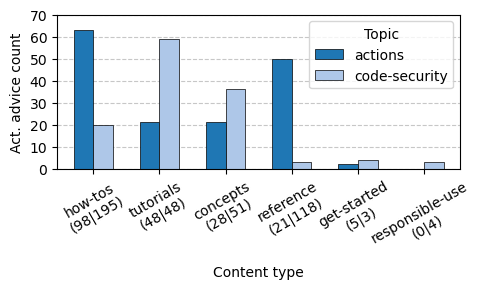

In [30]:
# Group by kind with bars for each topic side-by-side
actionable = merged_df[merged_df["actionable"]]
actionable = actionable[actionable.topic != "packages"]
actionable["kind"] = actionable["kind"].map(lambda x: "get-started" if "get" in x else x)
df_counts = actionable.groupby(['topic','kind']).size().reset_index(name='count')

# Pivot so each topic is a row and each kind a separate bar (columns)
pivot = df_counts.pivot(index='topic', columns='kind', values='count').fillna(0).astype(int)
df_kind = pivot.T.fillna(0).astype(int)  # kinds as rows, topics as columns

df_kind['total_sum'] = df_kind.sum(axis=1)
df_kind = df_kind.sort_values(by='total_sum', ascending=False).drop(columns=['total_sum'])

with open("all.files", "r") as f:
    paths = f.read().splitlines()
    df_doc_counts = pd.DataFrame(data=paths,columns=["file"])
    splits = df_doc_counts["file"].str.split("/",expand=True)
    df_doc_counts["topic"] = splits[0]
    df_doc_counts["kind"] = splits[1].map(lambda x: "get-started" if "get" in x else x)

full_docs = df_doc_counts.groupby(["topic","kind"]).size()
new_labels = []

# Loop over df_kind.index so the labels match your plot's X-axis perfectly
for kind in df_kind.index:
    # Use .get() with the (topic, kind) tuple. It safely returns 0 if the combo is missing.
    count_a = full_docs.get(("actions", kind), 0)
    count_b = full_docs.get(("code-security", kind), 0)
    
    # Format the new label (added parenthesis for cleaner reading, but you can remove them!)
    new_labels.append(f"{kind}\n({count_a}|{count_b})")

# Reassign to your plot dataframe
df_kind.index = new_labels

# Set up colors
cmap = plt.get_cmap("tab20")
colors = [cmap(i) for i in range(len(df_kind.columns))]

# Plot
ax = df_kind.plot(
    kind="bar",
    figsize=(5, 3),
    width=0.6,               
    color=colors,
    edgecolor="black",
    linewidth=0.5,
)

ax.set_xlabel("Content type")
ax.set_ylabel("Act. advice count")

# --- NEW: Move legend inside (upper right), taking advantage of the empty space ---
ax.legend(title="Topic", loc="upper right")

ax.tick_params(axis="x", rotation=30)

# Dashed horizontal lines at each y-tick
ax.set_axisbelow(True)
yticks = ax.get_yticks()
ax.set_yticks(yticks)
ax.grid(axis="y", linestyle="--", linewidth=0.8, alpha=0.7)

plt.tight_layout()
plt.savefig("content-type-stats.pdf", bbox_inches="tight")
plt.show()

In [31]:
# Actionable-only view
actionable_all = merged_df[merged_df["actionable"]].copy()
non_actionable_all = merged_df[~merged_df["actionable"]].copy()

# Flags from final_classification
actionable_all["is_owasp"] = actionable_all["final_classification"].apply(has_owasp)
actionable_all["is_plus"] = actionable_all["final_classification"].apply(has_plus)

# 3 exclusive classes:
# 1) OWASP only
# 2) + only (outside OWASP)
# 3) OWASP and +
actionable_all["owasp_plus_class"] = np.select(
    [
        actionable_all["is_owasp"] & actionable_all["is_plus"],
        actionable_all["is_owasp"] & ~actionable_all["is_plus"],
        ~actionable_all["is_owasp"] & actionable_all["is_plus"],
    ],
    [
        "OWASP_and_plus",
        "OWASP_only",
        "plus_only_outside_owasp",
    ],
    default="other_actionable",
)

class_order = ["OWASP_only", "plus_only_outside_owasp", "OWASP_and_plus", "other_actionable"]

# 1) Overall counts
overall_counts = (
    actionable_all["owasp_plus_class"]
    .value_counts()
    .reindex(class_order, fill_value=0)
    .rename("count")
    .to_frame()
)
overall_counts.loc["total_actionable"] = len(actionable_all)
overall_counts.loc["total_non_actionable"] = len(non_actionable_all)
overall_counts.loc["total_all"] = len(merged_df)

print("Overall counts:")
display(overall_counts)

# 2) Per-topic actionable class counts
topic_breakdown = (
    pd.crosstab(actionable_all["topic"], actionable_all["owasp_plus_class"])
    .reindex(columns=class_order, fill_value=0)
)
topic_breakdown["total_actionable"] = topic_breakdown.sum(axis=1)

# Add non-actionable per topic
topic_non_actionable = (
    non_actionable_all.groupby("topic").size().rename("non_actionable")
)

topic_breakdown = topic_breakdown.join(topic_non_actionable, how="outer").fillna(0).astype(int)
topic_breakdown["total_all"] = topic_breakdown["total_actionable"] + topic_breakdown["non_actionable"]
topic_breakdown = topic_breakdown.sort_values("total_all", ascending=False)

print("Per-topic breakdown (actionable classes + non-actionable):")
display(topic_breakdown)

# 3) Per-topic percentages within actionable only
topic_pct = (
    topic_breakdown[class_order]
    .div(topic_breakdown["total_actionable"].replace(0, np.nan), axis=0)
    .mul(100)
    .round(2)
    .fillna(0)
)
topic_pct.columns = [f"{c}_pct" for c in topic_pct.columns]

print("Per-topic actionable percentages:")
display(topic_pct)

NameError: name 'has_owasp' is not defined

# What advices point to the secure use reference?

In [32]:
link_pattern = re.compile(r"(?<!\!)\[([^\]]+)\]\(([^)]+)\)")
mask = merged_df["true_text"].str.contains(
    link_pattern.pattern, regex=True, na=False
)
link_extractions = merged_df.loc[mask].copy()

def _extract_pairs(s):
    if pd.isna(s):
        return []
    return link_pattern.findall(s)

link_extractions["links"] = link_extractions["true_text"].map(_extract_pairs)
link_extractions["link_text"] = link_extractions["links"].map(
    lambda pairs: [t for t, u in pairs]
)
link_extractions["link_url"] = link_extractions["links"].map(
    lambda pairs: [u for t, u in pairs]
)
link_extractions["count"] = link_extractions["link_url"].apply(lambda x:len(x))
link_extractions.drop(columns=["links"], inplace=True)
print(f"Rows with potential markdown links: {len(link_extractions)}")
link_extractions[
    [
        "count",
        "document_id",
        "alignment_status",
        "true_text",
        "link_text",
        "link_url",
    ]
][link_extractions["count"] > 1]

Rows with potential markdown links: 206


/var/folders/79/zj7smr4j2j324rn23rdq18n80000gn/T/ipykernel_9676/2546474261.py:2: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  mask = merged_df["true_text"].str.contains(


,count,document_id,alignment_status,true_text,link_text,link_url
6,3,actions/concepts/security/compromised-runners.md,match_fuzzy,This list describes the recommended approaches...,[Use GITHUB\\\_TOKEN for authentication in wor...,[/en/actions/security-guides/automatic-token-a...
13,3,actions/concepts/security/script-injections.md,match_exact,"When creating workflows, [custom actions](/en/...","[custom actions, composite actions, `github` c...",[/en/actions/creating-actions/about-custom-act...
25,2,actions/get-started/continuous-deployment.md,match_exact,GitHub Actions provides features that give you...,"[Deploying with GitHub Actions, Managing envir...",[/en/actions/deployment/about-deployments/depl...
29,3,actions/how-tos/create-and-publish-actions/rel...,match_exact,"**Note:** for security reasons, workflows trig...","[manual trigger, `pull_request_target`, Events...",[/en/actions/using-workflows/events-that-trigg...
61,2,actions/how-tos/secure-your-work/security-hard...,match_exact,"For security hardening, make sure you've revie...","[OpenID Connect, OpenID Connect]",[/en/actions/deployment/security-hardening-you...
66,2,actions/how-tos/secure-your-work/security-hard...,match_exact,"For security hardening, make sure you've revie...","[Configuring the OIDC trust with the cloud, Co...",[/en/actions/deployment/security-hardening-you...
73,2,actions/how-tos/secure-your-work/security-hard...,match_exact,"To be secure, you need to set a Claims JSON in...","[AUTOTITLE, OpenID Connect]",[https://jfrog.com/help/r/jfrog-platform-admin...
83,2,actions/how-tos/secure-your-work/use-artifact-...,match_exact,"> \[!NOTE] Before proceeding, ensure you have ...","[`attest-build-provenance` action, Generating ...",[https://github.com/actions/attest-build-prove...
91,2,actions/how-tos/write-workflows/choose-what-wo...,match_fuzzy,> \[!NOTE] > We recommend that you use a SHA v...,"[Secure use reference, About Dependabot alerts]",[/en/actions/security-guides/security-hardenin...
102,2,actions/reference/runners/github-hosted-runner...,match_exact,Since there are so many IP address ranges for ...,"[Using larger runners, Self-hosted runners]",[/en/actions/using-github-hosted-runners/about...


In [33]:
link_extractions.loc[420]["true_text"]

'Encouraging your users to keep push protection for users enabled in their personal account settings, so that no matter which public repository they push to, they are protected. For more information, see [Push protection for users](/en/code-security/secret-scanning/working-with-secret-scanning-and-push-protection/push-protection-for-users).'

In [34]:
link_extractions.loc[172]["true_text"]

'When creating workflows and actions, you should always consider whether your code might execute untrusted input from possible attackers. Certain contexts should be treated as untrusted input, as an attacker could insert their own malicious content. For more information, see [Secure use reference](/en/actions/security-guides/security-hardening-for-github-actions#understanding-the-risk-of-script-injections).'

In [35]:
secure_use_refs = link_extractions[
    link_extractions["link_text"].apply(lambda x: any("secure use reference" in text.lower() for text in x))
]
secure_use_refs

,document_id,extraction_text,owasp_classification,final_classification,text,alignment_status,extraction_index,group_index,char_interval.start_pos,char_interval.end_pos,...,cluster_id,cluster_score,unique,context_window,has_visual_alert,has_visual_alert_org,type,link_text,link_url,count
14,actions/concepts/security/script-injections.md,By adopting the same defensive programming pos...,[],[OWASP/4.2.1],# Script injections Understand the security r...,match_exact,2,1,1190,1551,...,14,100.000000,True,By adopting the same defensive programming pos...,False,False,<NA>,[Secure use reference],[/en/actions/security-guides/security-hardenin...,1
16,actions/concepts/security/script-injections.md,"For best practices keeping runners secure, see...",[],[],# Script injections Understand the security r...,match_exact,4,3,3153,3322,...,16,100.000000,True,"For best practices keeping runners secure, see...",False,False,<NA>,[Secure use reference],[/en/actions/reference/secure-use-reference#go...,1
21,actions/concepts/workflows-and-actions/context...,> \[!WARNING] > When creating workflows and ac...,[],[OWASP/4.1.1],# Contexts Learn about contexts in GitHub Act...,match_exact,1,0,735,1160,...,21,100.000000,True,"When creating workflows and actions, you shou...",True,True,WARNING,[Secure use reference],[/en/actions/security-guides/security-hardenin...,1
22,actions/concepts/workflows-and-actions/express...,> [!WARNING] > When creating workflows and act...,[OWASP/4.4.1],[OWASP/4.1.1],# Expressions You can evaluate expressions in...,match_fuzzy,1,0,1106,1531,...,21,100.000000,False,"When creating workflows and actions, you shou...",True,True,WARNING,[Secure use reference],[/en/actions/security-guides/security-hardenin...,1
23,actions/concepts/workflows-and-actions/reusing...,If you use a commit SHA when referencing the r...,"[OWASP/3.3.1, OWASP/3.3.2, OWASP/3.3.3, OWASP/...","[OWASP/3.3.2, OWASP/9.2.1]",# Reusing workflow configurations Learn how t...,match_exact,1,0,7398,7826,...,22,100.000000,True,If you use a commit SHA when referencing the r...,False,False,<NA>,[Secure use reference],[/en/actions/security-guides/security-hardenin...,1
31,actions/how-tos/create-and-publish-actions/rel...,Use GitHub's security features to communicate ...,[],[+],# Releasing and maintaining actions You can l...,match_exact,3,2,7104,7373,...,30,100.000000,True,Use GitHub's security features to communicate ...,False,False,<NA>,[Secure use reference],[/en/actions/security-guides/using-githubs-sec...,1
45,actions/how-tos/manage-runners/self-hosted-run...,We recommend that you only use self-hosted run...,"[OWASP/4.2.1, OWASP/4.2.2]",[OWASP/4.2.2],# Adding self-hosted runners You can add a se...,match_fuzzy,1,0,132,541,...,44,100.000000,True,We recommend that you only use self-hosted ru...,True,False,WARNING,[Secure use reference],[/en/actions/security-for-github-actions/secur...,1
47,actions/how-tos/manage-runners/self-hosted-run...,We recommend that you only use self-hosted run...,"[OWASP/4.2.1, OWASP/4.2.2]",[OWASP/4.2.2],# Managing access to self-hosted runners using...,match_fuzzy,1,0,233,642,...,44,100.000000,False,We recommend that you only use self-hosted ru...,True,False,WARNING,[Secure use reference],[/en/actions/security-for-github-actions/secur...,1
48,actions/how-tos/manage-runners/self-hosted-run...,We recommend that you only use self-hosted run...,"[OWASP/4.2.1, OWASP/4.2.2]",[OWASP/4.2.2],# Managing access to self-hosted runners using...,match_fuzzy,1,0,233,642,...,44,100.000000,False,We recommend that you only use self-hosted ru...,True,False,WARNING,[Secure use reference],[/en/actions/security-for-github-actions/secur...,1
53,actions/how-tos/reuse-automations/reuse-workfl...,Using the commit SHA is the safest option for ...,"[OWASP/3.3.1, OWASP/3.3.2, OWASP/3.3.3, OWASP/...",[OWASP/3.3.3],# Reuse workflows Learn how to avoid duplicat...,match_exact,1,0,4005,4221,...,50,100.000000,True,Using the commit SHA is the safest option for ...,False,False,<NA>,[Sec

#172	actions/tutorials/create-actions/create-a-java...	match_exact	When creating workflows and actions, you shoul...	[Secure use reference]	[/en/actions/security-guides/security-hardenin.

# Completeness

In [36]:
# Filter for secure-use reference documents
secure_use_df = merged_df[merged_df["document_id"].str.contains("secure-use", regex=False)].copy()

# Separate actionable and non-actionable
actionable = secure_use_df[secure_use_df["actionable"]]
non_actionable = secure_use_df[~secure_use_df["actionable"]]

print(f"Total extractions in secure-use reference: {len(secure_use_df)}")
print(f"Actionable: {len(actionable)}")
print(f"Non-actionable: {len(non_actionable)}\n")

print("=" * 100)
print("NON-ACTIONABLE EXTRACTIONS (highlighted):")
print("=" * 100)
for idx, row in non_actionable.iterrows():
    print(f"\n[NON-ACTIONABLE] Index {idx}")
    print(f"  Document: {row['document_id']}")
    print(f"  Extraction: {row['true_text'][:100]}...")
    print(f"  OWASP Classification: {row['owasp_classification']}")
    print(f"  Final Classification: {row['final_classification']}")
    print(f"  Alignment Status: {row['alignment_status']}")

print("\n" + "=" * 100)
print(f"ACTIONABLE EXTRACTIONS: {len(actionable)} total")
print("=" * 100)
for idx, row in actionable.iterrows():
    print(f"\n[ACTIONABLE] Index {idx}")
    print(f"  {row['true_text'][:80]}...")

Total extractions in secure-use reference: 26
Actionable: 26
Non-actionable: 0

NON-ACTIONABLE EXTRACTIONS (highlighted):

ACTIONABLE EXTRACTIONS: 26 total

[ACTIONABLE] Index 111
  Any user with write access to your repository has read access to all secrets con...

[ACTIONABLE] Index 112
  Actions can use the `GITHUB_TOKEN` by accessing it from the `github.token` conte...

[ACTIONABLE] Index 113
  Sensitive data should **never** be stored as plaintext in workflow files. Mask a...

[ACTIONABLE] Index 114
  Redacting of secrets is performed by your workflow runners. This means a secret ...

[ACTIONABLE] Index 115
  Structured data can cause secret redaction within logs to fail, because redactio...

[ACTIONABLE] Index 116
  If a secret is used to generate another sensitive value within a workflow, that ...

[ACTIONABLE] Index 117
  Registering secrets applies to any sort of transformation/encoding as well. If y...

[ACTIONABLE] Index 118
  Audit how secrets are used, to help ensure they’

In [37]:

# Find texts in the notebook that are similar to the Secure use reference entries

def normalize_text(text):
    return str(text).strip().lower()

secure_reps = secure_use_df["true_text"].map(normalize_text).dropna().tolist()

candidate_df = merged_df[~merged_df["document_id"].str.contains("secure-use", regex=False)].copy()
candidate_df["normalized_text"] = candidate_df["true_text"].map(normalize_text)

matches = []
for _, row in candidate_df.iterrows():
    match = process.extractOne(
        row["normalized_text"],
        secure_reps,
        scorer=fuzz.token_sort_ratio,
        score_cutoff=50,
    )
    if match:
        best_text, score, best_idx = match
        matches.append(
            {
                "document_id": row["document_id"],
                "true_text": row["true_text"],
                "best_secure_use_match": secure_use_df.iloc[best_idx]["true_text"],
                "score": score,
                "alignment_status": row["alignment_status"],
                "topic": row["topic"],
                "kind": row["kind"],
            }
        )

secure_use_similar_df = (
    pd.DataFrame(matches)
    .sort_values(["score", "document_id"], ascending=[False, True])
    .reset_index(drop=True)
)

secure_use_similar_df.groupby(by="best_secure_use_match").size()

best_secure_use_match
Actions can use the `GITHUB_TOKEN` by accessing it from the `github.token` context. For more information, see [Contexts reference](/en/actions/learn-github-actions/contexts#github-context). You should therefore make sure that the `GITHUB_TOKEN` is granted the minimum required permissions. It's good security practice to set the default permission for the `GITHUB_TOKEN` to read access only for repository contents. The permissions can then be increased, as required, for individual jobs within the workflow file.                                                                                                                                                                                  12
Although pinning to a commit SHA is the most secure option, specifying a tag is more convenient and is widely used. If you’d like to specify a tag, then be sure that you trust the action's creators. The ‘Verified creator’ badge on GitHub Marketplace is a useful signal, as it indicate

# Examples and alerts

In [38]:
# find extractions containing red```python
# find extractions containing redaction markers like [REDACTED@<number>] (case-insensitive)
REDACTED_PATTERN = re.compile(r"\[REDACTED@\d+\]", flags=re.IGNORECASE)

mask = (
    merged_df["true_text"].fillna("").str.contains(REDACTED_PATTERN)
    | merged_df["extraction_text"].fillna("").str.contains(REDACTED_PATTERN)
)

redacted_df = merged_df.loc[mask].copy()
redacted_df["redactions"] = (
    redacted_df["true_text"].fillna("").str.findall(REDACTED_PATTERN)
)

print(f"Found {len(redacted_df)} rows with redaction markers")
cols = [
    "document_id",
    # "true_text",
    "redactions",
    # "owasp_sbp"
]
print(redacted_df[cols].reset_index(drop=True).to_csv())

Found 8 rows with redaction markers
,document_id,redactions
0,actions/how-tos/deploy/deploy-to-third-party-platforms/sign-xcode-applications.md,['[REDACTED@3]']
1,actions/how-tos/secure-your-work/security-harden-deployments/oidc-in-jfrog.md,['[REDACTED@0]']
2,actions/how-tos/secure-your-work/use-artifact-attestations/increase-security-rating.md,['[REDACTED@0]']
3,actions/reference/security/secure-use.md,['[REDACTED@0]']
4,actions/reference/security/secure-use.md,['[REDACTED@1]']
5,code-security/how-tos/scan-code-for-vulnerabilities/troubleshooting/troubleshooting-analysis-errors/unnecessary-step-found.md,['[REDACTED@1]']
6,code-security/how-tos/secure-your-supply-chain/troubleshoot-dependency-security/troubleshooting-the-detection-of-vulnerable-dependencies.md,['[REDACTED@0]']
7,packages/working-with-a-github-packages-registry/working-with-the-nuget-registry.md,['[REDACTED@0]']



# Everything with ..

In [44]:
# Find actionable extractions containing "SHA" or "tag" (case-insensitive)
mask = (
    merged_df["actionable"]
    & (
        merged_df["true_text"].str.contains("SHA") | merged_df["true_text"].str.contains("tag ",case=False) | merged_df["true_text"].str.contains(" tag ",case=False)
    )
)
matches = merged_df[mask].copy()
print(f"Found {len(matches)} actionable extraction(s) containing 'SHA' or 'tag'")
#matches[["document_id", "true_text", "extraction_text", "alignment_status", "final_classification"]].reset_index(drop=True)
for item in matches["true_text"].to_list():
    print("=" * 50)
    print(item)

Found 14 actionable extraction(s) containing 'SHA' or 'tag'
If you use a commit SHA when referencing the reusable workflow, you can ensure that everyone who reuses that workflow will always be using the same YAML code. However, if you reference a reusable workflow by a tag or branch, be sure that you can trust that version of the workflow. For more information, see [Secure use reference](/en/actions/security-guides/security-hardening-for-github-actions#reusing-third-party-workflows).
Each Git commit receives a calculated SHA value, which is unique and immutable. Your action's users might prefer to rely on a commit's SHA value, as this approach can be more reliable than specifying a tag, which could be deleted or moved. However, this means that users will not receive further updates made to the action. You must use a commit's full SHA value, and not an abbreviated value.
Using the commit SHA is the safest option for stability and security. For more information, see [Secure use reference

In [45]:
# Find actionable extractions containing "SHA" or "tag" (case-insensitive)
mask = (
    merged_df["actionable"]
    & (
        merged_df["true_text"].str.contains("injection",case=False)
    )
)
matches = merged_df[mask].copy()
print(f"Found {len(matches)} actionable extraction(s) containing 'SHA' or 'tag'")
#matches[["document_id", "true_text", "extraction_text", "alignment_status", "final_classification"]].reset_index(drop=True)
for item in matches["true_text"].to_list():
    print("=" * 50)
    print(item)

Found 9 actionable extraction(s) containing 'SHA' or 'tag'
> \[!WARNING]
> When creating workflows and actions, you should always consider whether your code might execute untrusted input from possible attackers. Certain contexts should be treated as untrusted input, as an attacker could insert their own malicious content. For more information, see [Secure use reference](/en/actions/security-guides/security-hardening-for-github-actions#understanding-the-risk-of-script-injections).
> \[!WARNING]
> When creating workflows and actions, you should always consider whether your code might execute untrusted input from possible attackers. Certain contexts should be treated as untrusted input, as an attacker could insert their own malicious content. For more information, see [Secure use reference](/en/actions/security-guides/security-hardening-for-github-actions#understanding-the-risk-of-script-injections).
When creating workflows and actions, you should always consider whether your code might e

In [46]:
# Find actionable extractions containing "SHA" or "tag" (case-insensitive)
mask = (
    merged_df["actionable"]
    & (
        merged_df["true_text"].str.contains("pull_request_target",case=False)
    )
)
matches = merged_df[mask].copy()
print(f"Found {len(matches)} actionable extraction(s) containing 'SHA' or 'tag'")
#matches[["document_id", "true_text", "extraction_text", "alignment_status", "final_classification"]].reset_index(drop=True)
for item in matches["true_text"].to_list():
    print("=" * 50)
    print(item)

Found 1 actionable extraction(s) containing 'SHA' or 'tag'
Running untrusted code on the `pull_request_target` trigger may lead to security vulnerabilities. These vulnerabilities include cache poisoning and granting unintended access to write privileges or secrets. For more information, see [Secure use reference](/en/enterprise-cloud@latest/actions/reference/security/secure-use#mitigating-the-risks-of-untrusted-code-checkout) in the GitHub Enterprise Cloud documentation, and [Preventing pwn requests](https://securitylab.github.com/research/github-actions-preventing-pwn-requests) on the GitHub Security Lab website.


Not good:

```json 
{
  "document_id": "actions/how-tos/create-and-publish-actions/release-and-maintain-actions.md",
  "extraction_text": "**Note:** for security reasons, workflows triggered by `pull_request` from forks have restricted `GITHUB_TOKEN` permissions and do not have access to secrets. If your tests or other workflows triggered upon pull request require access to secrets, consider using a different event like a [manual trigger](/en/actions/using-workflows/events-that-trigger-workflows#manual-events) or a [`pull_request_target`](/en/actions/using-workflows/events-that-trigger-workflows#pull_request_target). For more information, see [Events that trigger workflows](/en/actions/using-workflows/events-that-trigger-workflows#pull-request-events-for-forked-repositories).\n",
  "owasp_classification": [
    "OWASP/4.1.1",
    "OWASP/4.2.3"
  ],
  "final_classification": [
  ]
}

```

In [ ]:
from itertools import combinations
import numpy as np
import pandas as pd

# Additional analyses summary cell


def analyze_additional_properties():
    out = {}

    # 1) Per-topic actionable rate and fuzzy rate
    df = merged_df.copy()
    df["is_fuzzy"] = df["alignment_status"] == "match_fuzzy"
    topic_stats = (
        df.groupby("topic")
        .agg(
            total=("document_id", "size"),
            actionable_count=("actionable", "sum"),
            fuzzy_count=("is_fuzzy", "sum"),
        )
        .assign(
            actionable_pct=lambda d: (d["actionable_count"] / d["total"] * 100).round(2),
            fuzzy_pct=lambda d: (d["fuzzy_count"] / d["total"] * 100).round(2),
        )
        .sort_values("total", ascending=False)
    )
    out["topic_stats"] = topic_stats

    # 2) Extraction length distribution and percentiles
    df["true_len"] = df["true_text"].fillna("").str.len()
    length_stats = df["true_len"].describe(percentiles=[0.25,0.5,0.75,0.9]).to_frame(name="value").T
    out["length_stats"] = length_stats

    # 3) Per-document coverage of extracted spans (union of intervals / doc length)
    def union_length(intervals):
        if not intervals:
            return 0
        ints = sorted(intervals, key=lambda x: x[0])
        merged = []
        cur_s, cur_e = ints[0]
        for s, e in ints[1:]:
            if s <= cur_e:
                cur_e = max(cur_e, e)
            else:
                merged.append((cur_s, cur_e))
                cur_s, cur_e = s, e
        merged.append((cur_s, cur_e))
        return sum(e - s for s,e in merged)

    docs = []
    for doc_id, group in df.groupby("document_id"):
        text_len = int(group["text"].dropna().iloc[0].__len__()) if len(group["text"].dropna()) else np.nan
        intervals = group.dropna(subset=["char_interval.start_pos","char_interval.end_pos"])[["char_interval.start_pos","char_interval.end_pos"]].apply(tuple, axis=1).tolist()
        cov = union_length(intervals)
        docs.append((doc_id, text_len, cov, round(cov / text_len * 100, 2) if text_len and text_len>0 else np.nan))
    doc_coverage = pd.DataFrame(docs, columns=["document_id","text_len","extracted_chars","coverage_pct"]).sort_values("coverage_pct", ascending=False)
    out["doc_coverage_top"] = doc_coverage.head(20)

    # 4) OWASP co-occurrence matrix (counts of codes appearing together in same extraction)
    def extract_owasp_list(v):
        if isinstance(v, list):
            return [str(x) for x in v if isinstance(x, str) and x.startswith("OWASP/")]
        if pd.isna(v):
            return []
        s = str(v)
        return [s] if s.startswith("OWASP/") else []
    owasp_lists = df["final_classification"].apply(extract_owasp_list)
    codes = {}
    for lst in owasp_lists:
        for a,b in combinations(sorted(set(lst)),2):
            codes.setdefault((a,b),0)
            codes[(a,b)] += 1
    # pivot to DataFrame adjacency
    uniq = sorted({c for pair in codes.keys() for c in pair})
    adj = pd.DataFrame(0, index=uniq, columns=uniq)
    for (a,b),cnt in codes.items():
        adj.loc[a,b] = cnt
        adj.loc[b,a] = cnt
    out["owasp_cooccurrence"] = adj

    # 5) Cluster compactness and size distribution from cluster_summary (if available)
    if "cluster_id" in cluster_summary.columns and "similarity_scores" in cluster_summary.columns:
        cs = cluster_summary.copy()
        cs["avg_score"] = cs["similarity_scores"].apply(lambda lst: float(np.mean(lst)) if isinstance(lst, (list,np.ndarray)) and len(lst)>0 else np.nan)
        cs_stats = cs.agg({"count":["min","max","mean","median"], "avg_score":["min","max","mean"]})
        out["cluster_summary_stats"] = cs_stats
        out["cluster_size_dist"] = cs["count"].value_counts().sort_index()

    # 6) Overlap: visual alerts vs links vs redactions
    visual_and_links = 0
    visual_and_links = int(((visual_alert_df.index.isin(link_extractions.index)) & visual_alert_df["has_visual_alert"]).sum()) if "link_extractions" in globals() else np.nan
    # safer: compute using merged_df flags
    has_link_mask = merged_df.index.isin(link_extractions.index) if "link_extractions" in globals() else (merged_df["true_text"].str.contains(r"\[.*\]\(.*\)", regex=True, na=False))
    visual_link_overlap = int(((merged_df["has_visual_alert"].fillna(False)) & has_link_mask).sum()) if "has_visual_alert" in merged_df.columns else np.nan
    redactions_by_topic = redacted_df.groupby("topic").size().sort_values(ascending=False) if "redacted_df" in globals() else pd.Series(dtype=int)
    out["visual_link_overlap"] = visual_link_overlap
    out["redactions_by_topic"] = redactions_by_topic

    # 7) Fuzzy/exact ratio by kind and topic
    fuzzy_by_kind = df.groupby("kind").agg(total=("document_id","size"), fuzzy=("is_fuzzy","sum")).assign(fuzzy_pct=lambda d: (d["fuzzy"]/d["total"]*100).round(2)).sort_values("total", ascending=False)
    out["fuzzy_by_kind"] = fuzzy_by_kind

    # 8) Quick list: top N documents with most unique clusters represented
    if "cluster_id" in df.columns:
        top_docs_cluster_diversity = df.dropna(subset=["cluster_id"]).groupby("document_id")["cluster_id"].nunique().sort_values(ascending=False).head(20)
        out["top_docs_cluster_diversity"] = top_docs_cluster_diversity

    # Print concise summary
    print("=== Topic actionable & fuzzy stats ===")
    display(topic_stats.head(10))
    print("\n=== Extraction length stats ===")
    display(length_stats)
    print("\n=== Top document coverage (extracted %) ===")
    display(out["doc_coverage_top"])
    print("\n=== OWASP co-occurrence (top pairs) ===")
    if not adj.empty:
        pairs = (adj.where(np.triu(np.ones(adj.shape), k=1).astype(bool))
                 .stack().sort_values(ascending=False).head(20))
        display(pairs)
    else:
        print("No OWASP co-occurrences found.")
    if "cluster_summary_stats" in out:
        print("\n=== Cluster stats ===")
        display(out["cluster_summary_stats"])
    print("\n=== Visual alert & link overlap ===")
    print("visual_link_overlap:", out["visual_link_overlap"])
    print("\n=== Redactions by topic (top) ===")
    display(out["redactions_by_topic"].head(10))
    print("\n=== Fuzzy by kind (top) ===")
    display(fuzzy_by_kind.head(10))

    return out

analysis_results = analyze_additional_properties()

=== Topic actionable & fuzzy stats ===


,total,actionable_count,fuzzy_count,actionable_pct,fuzzy_pct
topic,,,,,
code-security,241,125,6,51.87,2.49
actions,201,157,22,78.11,10.95
packages,17,6,2,35.29,11.76



=== Extraction length stats ===


,count,mean,std,min,25%,50%,75%,90%,max
value,459.0,382.858388,308.736345,51.0,229.0,335.0,468.0,599.8,4580.0



=== Top document coverage (extracted %) ===


...

,count,avg_score
min,1.000000,94.498949
max,8.000000,100.000000
mean,1.108696,99.959474
median,1.000000,NaN



=== Visual alert & link overlap ===
visual_link_overlap: 36

=== Redactions by topic (top) ===


topic
actions          5
code-security    2
packages         1
dtype: int64


=== Fuzzy by kind (top) ===


,total,fuzzy,fuzzy_pct
kind,,,
how-tos,148,13,8.78
tutorials,117,4,3.42
concepts,87,2,2.3
reference,73,8,10.96
responsible-use,10,1,10.0
working-with-a-github-packages-registry,7,0,0.0
getting-started,5,0,0.0
learn-github-packages,5,1,20.0
managing-github-packages-using-github-actions-workflows,5,1,20.0
